In [ ]:
 5.1: Add Common Noises to an Image

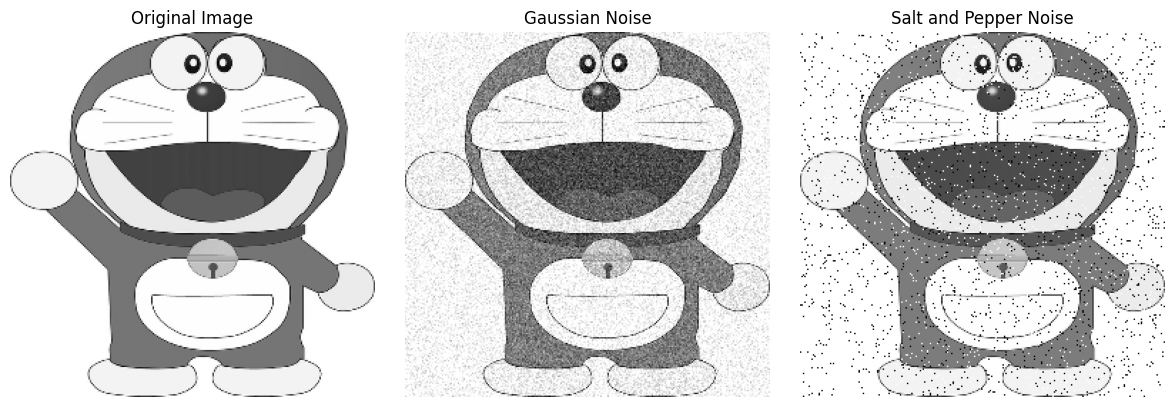

Assignment 5.1 Completed Successfully!
Output images saved.


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Load the original image
img = cv2.imread('/content/image.png', cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Image not found! Please upload image.png")

# Resize image
img = cv2.resize(img, (256, 256))

# Step 2: Add Gaussian Noise
mean = 0
sigma = 25

gaussian_noise = np.random.normal(
    mean, sigma, img.shape
)

gaussian_img = img.astype(np.float32) + gaussian_noise

gaussian_img = np.clip(gaussian_img, 0, 255)
gaussian_img = gaussian_img.astype(np.uint8)

# Step 3: Add Salt and Pepper Noise
sp_img = img.copy()

amount = 0.05

total_pixels = img.size
num_noise = int(amount * total_pixels)

num_salt = num_noise // 2
num_pepper = num_noise - num_salt

# Select unique random pixels
random_pixels = np.random.choice(
    total_pixels, num_noise, replace=False
)

salt_pixels = random_pixels[:num_salt]
pepper_pixels = random_pixels[num_salt:]

# Add white pixels (Salt)
sp_img.flat[salt_pixels] = 255

# Add black pixels (Pepper)
sp_img.flat[pepper_pixels] = 0

# Step 4: Display all images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gaussian_img, cmap='gray')
plt.title("Gaussian Noise")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(sp_img, cmap='gray')
plt.title("Salt and Pepper Noise")
plt.axis('off')

plt.tight_layout()
plt.show()

# Step 5: Save output images
cv2.imwrite('/content/Assignment_5_1_Gaussian_Noise.png', gaussian_img)
cv2.imwrite('/content/Assignment_5_1_Salt_Pepper_Noise.png', sp_img)

print("Assignment 5.1 Completed Successfully!")
print("Output images saved.")
